# Compare distributions, quantiles, and ensemble spread

Variation in a response and disagreement between fitted models are different things. We will fit a normal distribution and a quantile model to data with increasing noise, compare their prediction intervals, and then examine the spread of predictions from independently fitted NAMs.


## Generate data with changing spread

The response has a sine-shaped mean and a standard deviation that increases with x. We know both functions, so we can inspect how well the models recover the distribution as well as how well they predict held-out observations.


In [1]:
import logging
import warnings
logging.getLogger("lightning.pytorch").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", message=".*does not have many workers.*")
warnings.filterwarnings("ignore", message="You called.*self.log.*logger=True.*")
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

rng = np.random.default_rng(11)
X = pd.DataFrame({"x": rng.uniform(-1, 1, 1200)})
location = np.sin(3 * X.x)
scale = 0.12 + 0.35 * (X.x + 1) / 2
y = location + scale * rng.normal(size=len(X))
X_fit, X_test, y_fit, y_test = train_test_split(X, y, test_size=0.2, random_state=7)
X_train, X_val, y_train, y_val = train_test_split(X_fit, y_fit, test_size=0.25, random_state=8)
fit_options = dict(max_epochs=120, lr=0.01, batch_size=128, patience=20,
                   random_state=7, logger=False, enable_progress_bar=False,
                   enable_model_summary=False, checkpoint_path=tempfile.mkdtemp())


## Fit a normal distribution

NAMLSS learns a mean and a positive standard deviation for each input. The normal negative log likelihood contains log(sigma) + (y-mu)^2 / (2 sigma^2), apart from a constant. A larger scale reduces the standardized residual but incurs a larger log-scale term, so the model cannot improve the objective simply by widening every prediction.


In [2]:
from nampy.models import NAMLSS, QNAMLSS

normal = NAMLSS(family="normal", layer_sizes=[24, 12], dropout=0., numerical_preprocessing="minmax")
normal.fit(X_train, y_train, X_val=X_val, y_val=y_val, **fit_options)
parameters = normal.predict(X_test)
assert parameters.shape == (len(X_test), 2)
assert np.all(parameters[:, 1] > 0)
normal.predict_components(X_test).validate_additive_reconstruction(atol=1e-5)
metrics = normal.evaluate(X_test, y_test)
pd.DataFrame({"Test negative log likelihood": [metrics["NLL"]]}).style.hide(axis="index").format(precision=3)


/home/ad32/projects/package/NAMpy/nampy/models/_base.py:632: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  train_targets=torch.as_tensor(self.data_module.y_train),


Test negative log likelihood
0.132


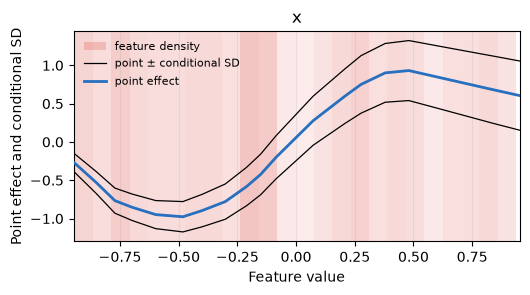

In [3]:
figures = normal.plot_distributional_effects(X_test, reference_X=X_train, feature_names=["x"])
plt.show()
plt.close("all")


The central curve shows the centered point effect. The surrounding curves are one conditional standard deviation above and below it. Their widening describes increasing response variability, rather than increasing uncertainty about the estimated curve.


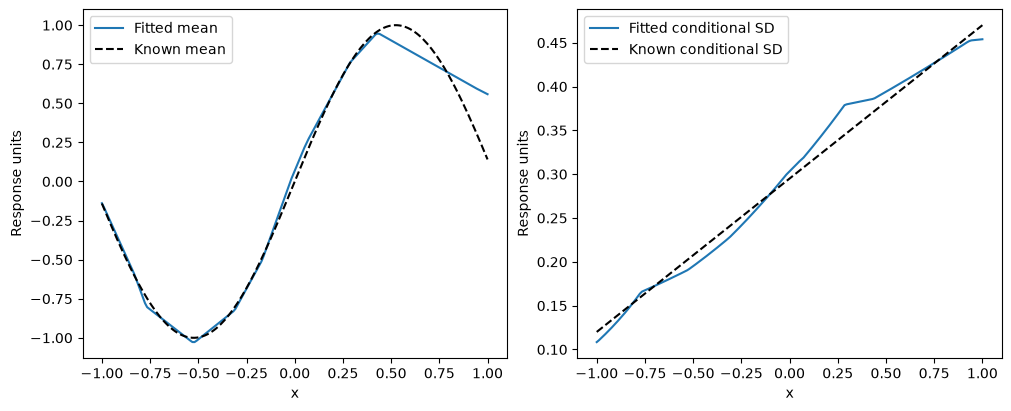

In [4]:
grid = pd.DataFrame({"x": np.linspace(-1, 1, 180)})
grid_mu, grid_sd = normal.predict(grid).T
figure, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
axes[0].plot(grid.x, grid_mu, label="Fitted mean")
axes[0].plot(grid.x, np.sin(3*grid.x), "k--", label="Known mean")
axes[1].plot(grid.x, grid_sd, label="Fitted conditional SD")
axes[1].plot(grid.x, .12+.35*(grid.x+1)/2, "k--", label="Known conditional SD")
for axis in axes:
    axis.set(xlabel="x", ylabel="Response units")
    axis.legend()
plt.show()
plt.close(figure)

Here the fitted standard deviation is plotted directly against the function used to generate the data. This reveals where the model overestimates or underestimates response spread.


## Compare 80% prediction intervals

The normal model gives an 80% interval through mu plus or minus approximately 1.282 times sigma. The quantile model estimates the 10th and 90th percentiles directly. It uses pinball loss and constrains the predicted quantiles to remain ordered.

We compare both intervals on the same 240 test observations, reporting their coverage and average width.


In [5]:
quantiles = QNAMLSS(layer_sizes=[24, 12], dropout=0., numerical_preprocessing="minmax",
                    distributional_kwargs={"quantiles": [0.1, 0.5, 0.9]})
quantiles.fit(X_train, y_train, X_val=X_val, y_val=y_val, **fit_options)
q = quantiles.predict(X_test)
assert np.all(np.diff(q, axis=1) >= -1e-6)
mu, sd = parameters.T
intervals = {"Normal 80%": (mu - 1.2815515655 * sd, mu + 1.2815515655 * sd),
             "Quantile 80%": (q[:, 0], q[:, 2])}
(pd.DataFrame([{"Interval": name, "Target coverage": .8, "Test coverage": np.mean((y_test >= lo) & (y_test <= hi)),
               "Mean width": np.mean(hi-lo)} for name,(lo,hi) in intervals.items()])).style.hide(axis="index").format({"Target coverage": "{:.0%}", "Test coverage": "{:.2%}", "Mean width": "{:.3f}"})


Interval,Target coverage,Test coverage,Mean width
Normal 80%,80%,77.50%,0.739
Quantile 80%,80%,91.25%,1.071


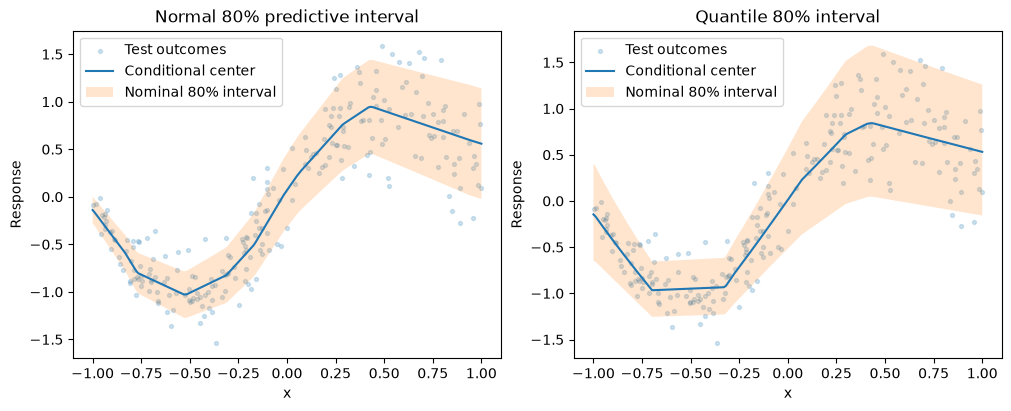

In [6]:
grid_q = quantiles.predict(grid)
figure, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for axis, name, center, lo, hi in [
    (axes[0], "Normal 80% predictive interval", grid_mu, grid_mu-1.2815515655*grid_sd, grid_mu+1.2815515655*grid_sd),
    (axes[1], "Quantile 80% interval", grid_q[:,1], grid_q[:,0], grid_q[:,2]),
]:
    axis.scatter(X_test.x, y_test, s=8, alpha=.2, label="Test outcomes")
    axis.plot(grid.x, center, label="Conditional center")
    axis.fill_between(grid.x, lo, hi, alpha=.2, label="Nominal 80% interval")
    axis.set(title=name, xlabel="x", ylabel="Response")
    axis.legend()
plt.show()
plt.close(figure)

The normal interval covers 77.5% of the test responses with mean width 0.739. The quantile interval covers 91.25% with mean width 1.071. The wider quantile interval overcovers relative to the 80% target; the normal interval is closer to that target on this normal-data simulation. Ordering the quantiles has prevented crossing, but has not made their coverage accurate.


## Compare independently fitted models

We now fit three NAMs independently and plot their average prediction with one standard deviation of member predictions on either side. This band describes disagreement among the fitted models. The observations can vary much more widely because they also contain response noise.


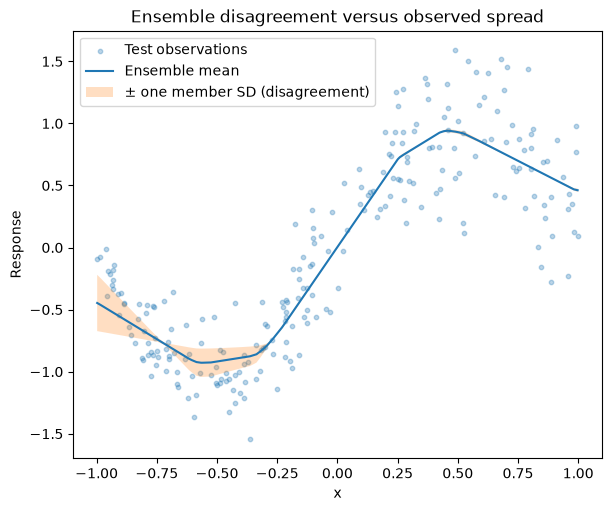

In [7]:
from nampy.models import NAMRegressor, NeuralEnsemble

ensemble = NeuralEnsemble(NAMRegressor(layer_sizes=[16, 8], dropout=0., numerical_preprocessing="minmax"),
                          n_estimators=3, random_state=17)
ensemble.fit(X_train, y_train, X_val=X_val, y_val=y_val, **fit_options)
uncertainty = ensemble.predict_component_uncertainty(X_test)
mean = uncertainty.mean.response
disagreement = uncertainty.response_std
order = np.argsort(X_test.x.to_numpy())
figure, axis = plt.subplots(figsize=(6, 5), constrained_layout=True)
axis.scatter(X_test.x, y_test, s=10, alpha=0.3, label="Test observations")
axis.plot(X_test.x.to_numpy()[order], mean[order], label="Ensemble mean")
axis.fill_between(X_test.x.to_numpy()[order], (mean-disagreement)[order], (mean+disagreement)[order],
                  alpha=0.25, label="± one member SD (disagreement)")
axis.set(xlabel="x", ylabel="Response", title="Ensemble disagreement versus observed spread")
axis.legend()
plt.show()
plt.close(figure)


Test responses, the ensemble mean, and plus/minus one standard deviation across member predictions. This disagreement band is not a prediction interval for a new response.
